# Technical Indicators under Test: Moving Averages, Channel Breakouts, Bollinger Bands, RSI, Stochastics and MACD on the S&P 500 since 1950 and Six ETFs, with White's Reality Check, Hansen's SPA Test and a Machine-Learning Combination

The CFA curriculum's technical-analysis reading describes the standard indicators: **moving averages** and their crossovers, **Bollinger bands**, momentum oscillators such as the **relative strength index (RSI)**, **stochastics** and **MACD**, and price channels. Each has parameters (window lengths, thresholds), and trying many combinations on the same history almost guarantees that one looks profitable. Brock, Lakonishok and LeBaron (1992) found that simple rules predicted the Dow Jones index in 1897–1986; Sullivan, Timmermann and White (1999) then showed how to test the **best of thousands of rules** honestly with **White's (2000) Reality Check**, and Hansen (2005) sharpened it into the **Superior Predictive Ability (SPA)** test.

This notebook applies them to:

- the **S&P 500 index since 1950**, split into 1950–1989 (the era of the early studies) and 1990–2026;
- six **ETFs since 2004–2007**: S&P 500, Nasdaq-100, Russell 2000, developed markets, long Treasuries and gold.

Steps:
1. **552 rules** in nine families, each turned into a daily long-or-flat position (traded on the next day's close, 5 bp per trade).
2. **The best rule and how good it looks** in each market and period, against buy-and-hold.
3. **Data-snooping tests:** Bonferroni and Holm corrections of the individual *t*-statistics, and the Reality Check and SPA *p*-values from 1,000 stationary-bootstrap resamples, which ask whether the *best* rule beats the benchmark once the search over all rules is accounted for.
4. **Machine learning:** LightGBM combining all indicator values to decide each day whether to hold the market, trained on earlier years and tested out of time.

**Data.** Yahoo Finance (S&P 500 index since 1950; SPY, QQQ, IWM, EFA, TLT, GLD); FRED (3-month Treasury bill rate, for cash returns).

**Methods.** Trading-rule backtests with costs, Sharpe ratios, Bonferroni and Holm corrections, White's Reality Check, Hansen's SPA test, the Politis–Romano stationary bootstrap, LightGBM classification with walk-forward retraining.

**Key output.** How many rules beat buy-and-hold before and after correcting for data snooping, in each period and market, and whether a machine-learning combination does better.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import logging
import lightgbm as lgb
import yfinance as yf
from scipy import stats as sst

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
COST_BPS = 5
ETFS = ["SPY", "QQQ", "IWM", "EFA", "TLT", "GLD"]
N_BOOT = 1000
# mean block length of the stationary bootstrap (trading days)
BLOCK = 10
ML_FIRST_TEST = 1990  # S&P 500 index: walk-forward test from 1990

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Data

In [3]:
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
PXD = cached(
    "yahoo_daily_technical",
    lambda: yf.download(
        ["^GSPC"] + ETFS,
        start="1950-01-01",
        interval="1d",
        auto_adjust=True,
        progress=False,
    )[["Close", "High", "Low"]],
    max_age_hours=24 * 7,
)
PXD.index = pd.to_datetime(PXD.index)
TB = cached(
    "fred_tbill",
    lambda: fred.get_series("DTB3").to_frame("tb"),
    max_age_hours=24 * 7,
)
TB.index = pd.to_datetime(TB.index)
rf_daily = (TB.tb.reindex(PXD.index).ffill() / 100 / 252).fillna(0)
MARKETS = {
    "S&P 500 index, 1950–1989": ("^GSPC", "1950-01-01", "1989-12-31"),
    "S&P 500 index, 1990–2026": ("^GSPC", "1990-01-01", "2026-12-31"),
}
for e in ETFS:
    MARKETS[f"{e}, since inception"] = (e, "2004-01-01", "2026-12-31")
print(
    f"S&P 500 index {PXD['Close']['^GSPC'].first_valid_index():%Y-%m-%d} →"
    f" {PXD.index.max():%Y-%m-%d}; ETFs from "
    + ", ".join(f"{e} {PXD['Close'][e].first_valid_index():%Y}" for e in ETFS)
    + ". The index excludes dividends; the ETFs include them."
)

S&P 500 index 1950-01-03 → 2026-11-12; ETFs from SPY 1993, QQQ 1999, IWM 2000, EFA 2001, TLT 2002, GLD 2004. The index excludes dividends; the ETFs include them.


## 3. The rule universe

Every rule gives a signal at each close: 1 = hold the asset, 0 = hold Treasury bills. The position is taken at the **next** close, so no rule uses information it would not have had. Each change of position costs 5 bp.

| Family | Rule | Parameters | Rules |
|---|---|---|---|
| Moving-average crossover | long when the short average is above the long one | short 1, 2, 5, 10, 20 days; long 50, 100, 150, 200, 250 days; band 0 or 1% | 50 |
| Channel breakout | long after a close above the *n*-day high, out after a close below the *n*-day low | 5, 10, 20, 50, 100, 150, 200, 250 days; exit window 0.5× or 1× | 16 |
| Filter rule | long after a rise of *x*% from the last low, out after a fall of *x*% from the last high | *x* = 0.5% … 20% (14 values) | 14 |
| Bollinger bands | mean reversion: long when the price falls below the lower band until it returns to the average; or breakout: long above the upper band | 10, 20, 50 days; 1.5, 2, 2.5 standard deviations; two styles | 18 |
| RSI | mean reversion: long when RSI falls below the lower threshold until it rises above the upper one; or momentum: long while RSI > 50 + *k* | 7, 14, 21, 28 days; thresholds 20/80, 25/75, 30/70; momentum *k* = 0, 5, 10 | 24 |
| Stochastics | long when %K crosses above %D below the oversold level, out when it crosses below above the overbought level | %K 5, 9, 14, 21; %D 3, 5; levels 20/80, 30/70 | 16 |
| MACD | long while the MACD line is above its signal line (or above zero) | fast 5, 8, 12, 19; slow 26, 35, 39, 50; signal 5, 9; two styles | 64 |
| Price above a moving average with a time filter | long while the close has been above the *n*-day average for *d* days | *n* = 10 … 250 (9 values); *d* = 1, 2, 5, 10, 20, 40 | 54 |
| Calendar | long only in some months / days | turn of the month, "sell in May", skipping one month or weekday | 20 |

All families together give 276 rules; each is also run **long–short** (short the asset instead of holding bills), for 552 in total.

In [4]:
def ma(x, n):
    return x.rolling(n, min_periods=n).mean()


def hold(enter, exit_):
    s = pd.Series(np.nan, index=enter.index)
    s[enter.fillna(False)] = 1.0
    s[exit_.fillna(False) & ~enter.fillna(False)] = 0.0
    return s.ffill().fillna(0)


def rules_for(c, h, l):
    R = {}
    for s in (1, 2, 5, 10, 20):
        for L in (50, 100, 150, 200, 250):
            for b in (0.0, 0.01):
                R[f"MA {s}/{L} band {b:.0%}"] = (
                    (ma(c, s) > ma(c, L) * (1 + b))
                    .astype(float)
                    .where(ma(c, L).notna(), 0)
                )
    for n in (5, 10, 20, 50, 100, 150, 200, 250):
        for ex in (0.5, 1.0):
            m = max(2, int(n * ex))
            R[f"channel {n} exit {m}"] = hold(
                c > c.shift(1).rolling(n).max(),
                c < c.shift(1).rolling(m).min(),
            )
    for x in (
        0.005,
        0.01,
        0.015,
        0.02,
        0.025,
        0.03,
        0.04,
        0.05,
        0.06,
        0.08,
        0.10,
        0.12,
        0.15,
        0.20,
    ):
        pos, lo, hi, out = 0, c.iloc[0], c.iloc[0], np.zeros(len(c))
        for i, p in enumerate(c.to_numpy()):
            if pos == 0:
                lo = min(lo, p)
                if p >= lo * (1 + x):
                    pos, hi = 1, p
            else:
                hi = max(hi, p)
                if p <= hi * (1 - x):
                    pos, lo = 0, p
            out[i] = pos
        R[f"filter {x:.1%}"] = pd.Series(out, index=c.index)
    for n in (10, 20, 50):
        sd = c.rolling(n).std()
        for k in (1.5, 2.0, 2.5):
            R[f"Bollinger {n},{k} reversion"] = hold(
                c < ma(c, n) - k * sd, c > ma(c, n)
            )
            R[f"Bollinger {n},{k} breakout"] = hold(
                c > ma(c, n) + k * sd, c < ma(c, n)
            )
    d = c.diff()
    for n in (7, 14, 21, 28):
        up, dn = (
            d.clip(lower=0).ewm(alpha=1 / n).mean(),
            (-d.clip(upper=0)).ewm(alpha=1 / n).mean(),
        )
        rsi = 100 - 100 / (1 + up / dn)
        for lo_, hi_ in ((20, 80), (25, 75), (30, 70)):
            R[f"RSI {n} reversion {lo_}/{hi_}"] = hold(rsi < lo_, rsi > hi_)
        for k in (0, 5, 10):
            R[f"RSI {n} momentum >{50 + k}"] = (rsi > 50 + k).astype(float)
    for kn in (5, 9, 14, 21):
        K = (
            100
            * (c - l.rolling(kn).min())
            / (h.rolling(kn).max() - l.rolling(kn).min())
        )
        for dn_ in (3, 5):
            D = K.rolling(dn_).mean()
            for lo_, hi_ in ((20, 80), (30, 70)):
                R[f"stochastic {kn},{dn_} {lo_}/{hi_}"] = hold(
                    (K > D) & (K.shift(1) <= D.shift(1)) & (K < lo_),
                    (K < D) & (K.shift(1) >= D.shift(1)) & (K > hi_),
                )
    for f in (5, 8, 12, 19):
        for s in (26, 35, 39, 50):
            m = c.ewm(span=f).mean() - c.ewm(span=s).mean()
            for sg in (5, 9):
                R[f"MACD {f}/{s}/{sg} signal"] = (
                    m > m.ewm(span=sg).mean()
                ).astype(float)
                R[f"MACD {f}/{s}/{sg} zero"] = (m > 0).astype(float)
    for n in (10, 20, 30, 50, 75, 100, 150, 200, 250):
        above = (c > ma(c, n)).astype(int)
        run = above.groupby((above != above.shift()).cumsum()).cumsum()
        for dd in (1, 2, 5, 10, 20, 40):
            R[f"above MA {n} for {dd}d"] = (
                (run >= dd).astype(float).where(ma(c, n).notna(), 0)
            )
    idx = c.index
    tom = pd.Series(idx.day, index=idx).le(3) | pd.Series(
        idx.day, index=idx
    ).ge(28)
    R["turn of month (28th–3rd)"] = tom.astype(float)
    for mo in range(1, 13):
        R[f"skip month {mo}"] = pd.Series(idx.month != mo, index=idx).astype(
            float
        )
    R["sell in May (Nov–Apr)"] = pd.Series(
        np.isin(idx.month, [11, 12, 1, 2, 3, 4]), index=idx
    ).astype(float)
    for wd in range(5):
        R[f"skip weekday {wd}"] = pd.Series(
            idx.weekday != wd, index=idx
        ).astype(float)
    R["Halloween and turn of month"] = (
        R["sell in May (Nov–Apr)"].astype(bool) | tom
    ).astype(float)
    R["buy and hold"] = pd.Series(1.0, index=idx)
    return pd.DataFrame(R)


def backtest(sig, r, rf, long_short=False):
    pos = sig.shift(1).fillna(0)
    if long_short:
        pos = 2 * pos - 1
        ret = pos * r + (1 - pos.abs()) * rf
    else:
        ret = pos * r + (1 - pos) * rf
    trades = pos.diff().abs().fillna(0)
    return ret - trades * COST_BPS / 1e4

In [5]:
def market_returns(tk, a, b):
    c, h, l = (PXD[k][tk].loc[:b].dropna() for k in ("Close", "High", "Low"))
    sig = rules_for(c, h, l)
    r = c.pct_change().fillna(0)
    rf = rf_daily.reindex(c.index).fillna(0)
    out = {}
    for name in sig.columns:
        out[name] = backtest(sig[name], r, rf)
        if name != "buy and hold":
            out[name + " (long–short)"] = backtest(
                sig[name], r, rf, long_short=True
            )
    D = pd.DataFrame(out).loc[a:b]
    # skip the first year, when long averages are not yet defined
    D = D.iloc[260:] if a in ("2004-01-01", "1950-01-01") else D
    return D, rf.reindex(D.index)


RET, RF = {}, {}
for k, v in MARKETS.items():
    RET[k], RF[k] = market_returns(*v)
print(
    f"{RET['S&P 500 index, 1990–2026'].shape[1] - 1} rules per market; "
    + ", ".join(f"{k}: {len(v):,} days" for k, v in RET.items())
)

552 rules per market; S&P 500 index, 1950–1989: 9,794 days, S&P 500 index, 1990–2026: 9,285 days, SPY, since inception: 5,493 days, QQQ, since inception: 5,493 days, IWM, since inception: 5,493 days, EFA, since inception: 5,493 days, TLT, since inception: 5,493 days, GLD, since inception: 5,271 days


## 4. The best rule, and whether it survives data snooping

For each market and period, every rule's daily return is compared with **buy-and-hold**: $d_{k,t} = r_{k,t} - r_{BH,t}$. The best rule is the one with the highest mean $\bar d_k$.

- **Naive *t*-test:** the best rule's own *t*-statistic, ignoring that it was chosen from 552.
- **Bonferroni and Holm:** the *p*-value multiplied by the number of rules (Holm applies it step by step).
- **White's Reality Check:** compares $\max_k \sqrt{T}\,\bar d_k$ with its distribution under the null that *no* rule beats the benchmark, obtained from 1,000 stationary-bootstrap resamples of the days (blocks of average length 10, preserving autocorrelation).
- **Hansen's SPA:** the same, with studentised statistics and with clearly bad rules removed from the null distribution, which makes the test more powerful.

A *p*-value below 0.05 means the best rule's outperformance is unlikely to be the product of searching.

In [6]:
rng = np.random.default_rng(SEED)


def stationary_indices(T, n, p):
    """
    Politis–Romano stationary bootstrap: blocks start at random days and have
    geometric lengths with mean 1/p.
    """
    idx = np.empty((n, T), dtype=np.int64)
    t = np.arange(T)
    for b in range(n):
        new = rng.random(T) < p
        new[0] = True
        seg = np.cumsum(new) - 1
        seg_t0 = t[new]
        seg_start = rng.integers(0, T, len(seg_t0))
        idx[b] = (seg_start[seg] + t - seg_t0[seg]) % T
    return idx


def snooping_tests(D, rf=None):
    EXR = D.sub(rf, axis=0) if rf is not None else D
    bh = D["buy and hold"].to_numpy()
    names = D.drop(columns="buy and hold").columns
    X = D[names].to_numpy() - bh[:, None]
    # rules that never differ from buy-and-hold are dropped
    live = X.std(0) > 1e-12
    X, names = X[:, live], names[live]
    T, K = X.shape
    mean = X.mean(0)
    sd = X.std(0, ddof=1)
    tstat = mean / sd * np.sqrt(T)
    best = int(np.argmax(mean))
    idx = stationary_indices(T, N_BOOT, 1 / BLOCK)
    Xc = X - mean
    # SPA: recentre only rules that are not clearly bad (Hansen's consistent
    # version)
    keep = mean >= -sd / np.sqrt(T) * np.sqrt(2 * np.log(np.log(T)))
    # bad rules keep their (negative) mean, so they cannot drive the maximum
    mu_c = np.where(keep, 0.0, mean)
    rc, spa = np.empty(N_BOOT), np.empty(N_BOOT)
    for b in range(N_BOOT):
        mb = X[idx[b]].mean(0)
        rc[b] = np.max(np.sqrt(T) * (mb - mean))
        spa[b] = max(np.max(np.sqrt(T) * (mb - mean + mu_c) / sd), 0)
    v_rc = np.sqrt(T) * mean.max()
    v_spa = max(np.max(np.sqrt(T) * mean / sd), 0)
    p = 2 * (1 - sst.t.cdf(np.abs(tstat), T - 1))
    order = np.argsort(p)
    holm = np.maximum.accumulate(np.minimum(1, p[order] * (K - np.arange(K))))
    holm_p = np.empty(K)
    holm_p[order] = holm
    ann = lambda r: (1 + r).prod() ** (252 / len(r)) - 1
    rb = D[names[best]]
    return {
        "rules": K,
        "best rule": names[best],
        "best rule % a year": ann(rb) * 100,
        "buy and hold % a year": ann(D["buy and hold"]) * 100,
        "best Sharpe": (
            EXR[names[best]].mean() / EXR[names[best]].std() * np.sqrt(252)
        ),
        "buy-and-hold Sharpe": (
            EXR["buy and hold"].mean()
            / EXR["buy and hold"].std()
            * np.sqrt(252)
        ),
        "rules beating buy-and-hold": int((mean > 0).sum()),
        "naive p (best)": p[best],
        "rules with naive p < 0.05": int(((p < 0.05) & (mean > 0)).sum()),
        "Bonferroni p (best)": min(1, p[best] * K),
        "Holm: rules significant": int(((holm_p < 0.05) & (mean > 0)).sum()),
        "Reality Check p": (rc >= v_rc).mean(),
        "SPA p": (spa >= v_spa).mean(),
    }


t0 = time.time()
SNOOP = pd.DataFrame({k: snooping_tests(v, RF[k]) for k, v in RET.items()}).T
print(f"{N_BOOT} bootstrap resamples per market ({time.time() - t0:.0f} s)")
SNOOP

1000 bootstrap resamples per market (47 s)


,rules,best rule,best rule % a year,buy and hold % a year,best Sharpe,buy-and-hold Sharpe,rules beating buy-and-hold,naive p (best),rules with naive p < 0.05,Bonferroni p (best),Holm: rules significant,Reality Check p,SPA p
"S&P 500 index, 1950–1989",552,filter 0.5% (long–short),17.66,7.47,0.90,0.21,189,0.00,13,1,1,0.10,0.01
"S&P 500 index, 1990–2026",552,skip month 9 (long–short),9.60,8.68,0.45,0.40,7,0.63,0,1,0,1.00,0.96
"SPY, since inception",552,RSI 28 reversion 30/70,13.18,10.87,0.80,0.55,5,0.60,0,1,0,0.99,0.98
"QQQ, since inception",548,skip month 9,15.11,14.99,0.69,0.67,0,0.96,0,1,0,1.00,1.00
"IWM, since inception",552,skip month 9 (long–short),10.08,8.63,0.45,0.39,3,0.63,0,1,0,1.00,0.98
"EFA, since inception",550,RSI 28 reversion 25/75 (long–short),9.08,6.19,0.43,0.31,12,0.24,0,1,0,0.96,0.71
"TLT, since inception",552,skip month 10 (long–short),5.67,2.80,0.33,0.14,57,0.12,0,1,0,0.91,0.49
"GLD, since inception",552,skip month 6 (long–short),12.70,9.84,0.64,0.51,4,0.28,0,1,0,0.98,0.83


### Sharpe ratio instead of mean return

Many rules spend long periods in Treasury bills, so they may earn less than buy-and-hold but with much lower risk. The same tests are repeated on **risk-adjusted** performance: each rule's return in excess of bills is scaled to the volatility of buy-and-hold's excess return before the comparison, so a rule wins only if its Sharpe ratio is higher. (The Sharpe ratios in this table are therefore computed on excess returns.)

In [7]:
def risk_scaled(D, rf):
    # excess returns over Treasury bills
    X = D.sub(rf, axis=0)
    vol_bh = X["buy and hold"].std()
    return X.apply(lambda c: c * vol_bh / c.std() if c.std() > 0 else c)


SNOOP_RS = pd.DataFrame(
    {k: snooping_tests(risk_scaled(v, RF[k])) for k, v in RET.items()}
).T
SNOOP_RS[[
    "best rule",
    "best Sharpe",
    "buy-and-hold Sharpe",
    "rules beating buy-and-hold",
    "rules with naive p < 0.05",
    "Holm: rules significant",
    "Reality Check p",
    "SPA p",
]]

,best rule,best Sharpe,buy-and-hold Sharpe,rules beating buy-and-hold,rules with naive p < 0.05,Holm: rules significant,Reality Check p,SPA p
"S&P 500 index, 1950–1989",filter 0.5%,1.09,0.21,229,76,9,0.02,0.00
"S&P 500 index, 1990–2026",RSI 28 reversion 30/70,0.60,0.40,41,0,0,0.87,0.72
"SPY, since inception",RSI 28 reversion 30/70,0.80,0.55,62,0,0,0.87,0.59
"QQQ, since inception",MA 1/150 band 0%,0.75,0.67,13,0,0,1.00,1.00
"IWM, since inception",RSI 28 reversion 30/70,0.55,0.39,11,0,0,0.98,0.96
"EFA, since inception",MA 20/200 band 1%,0.47,0.31,65,0,0,0.98,0.80
"TLT, since inception",MA 20/100 band 0%,0.34,0.14,85,0,0,0.95,0.60
"GLD, since inception",skip month 6 (long–short),0.64,0.51,27,0,0,0.99,0.81


## 5. A machine-learning combination

Rather than choosing one rule, **LightGBM** sees the value of every indicator on each day (moving-average gaps, channel positions, Bollinger *z*-scores, RSI, stochastics, MACD, recent returns and volatility) and predicts whether the S&P 500 index will beat Treasury bills over the next five days. It is retrained every January on all earlier data (walk-forward) and tested from 1990; the strategy holds the index when the predicted probability exceeds 50%. Because it is fitted to past data only, its result is free of the look-ahead in choosing the best rule, but it is itself one more rule, and judged against buy-and-hold.

In [8]:
c = PXD["Close"]["^GSPC"].dropna()
r = c.pct_change()
FE = pd.DataFrame({
    **{f"gap_ma{n}": c / ma(c, n) - 1 for n in (5, 10, 20, 50, 100, 200)},
    **{
        f"pos_ch{n}": (
            (c - c.rolling(n).min())
            / (c.rolling(n).max() - c.rolling(n).min())
        )
        for n in (20, 50, 250)
    },
    **{f"ret{n}": c / c.shift(n) - 1 for n in (1, 5, 20, 60, 120, 250)},
    **{f"vol{n}": r.rolling(n).std() for n in (10, 60)},
    "boll20": (c - ma(c, 20)) / c.rolling(20).std(),
    "macd": (c.ewm(span=12).mean() - c.ewm(span=26).mean()) / c,
    "month": c.index.month,
    "dom": c.index.day,
    "weekday": c.index.weekday,
})
for n in (7, 14, 28):
    d = c.diff()
    FE[f"rsi{n}"] = 100 - 100 / (
        1
        + d.clip(lower=0).ewm(alpha=1 / n).mean()
        / (-d.clip(upper=0)).ewm(alpha=1 / n).mean()
    )
rf = rf_daily.reindex(c.index).fillna(0)
fwd5 = (c.shift(-5) / c - 1) - rf.rolling(5).sum().shift(-5)
DF = FE.assign(y=(fwd5 > 0).astype(float).where(fwd5.notna())).dropna(
    subset=list(FE.columns)
)
prob = pd.Series(np.nan, index=DF.index)
for yr in range(ML_FIRST_TEST, DF.index.max().year + 1):
    tr = DF[(DF.index < f"{yr}-01-01")].iloc[:-5].dropna(subset=["y"])
    te = DF.index.year == yr
    m = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.02,
        num_leaves=15,
        min_child_samples=200,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        verbose=-1,
        random_state=SEED,
    ).fit(tr[FE.columns], tr.y)
    prob[te] = m.predict_proba(DF.loc[te, FE.columns])[:, 1]
sig = (prob > 0.5).astype(float).reindex(c.index).fillna(0)
test_idx = c.index[c.index >= f"{ML_FIRST_TEST}-01-01"]
ml_ret = backtest(sig, r.fillna(0), rf).loc[test_idx]
bh_ret = backtest(pd.Series(1.0, index=c.index), r.fillna(0), rf).loc[test_idx]
ann = lambda x: (1 + x).prod() ** (252 / len(x)) - 1
yt = DF.y.loc[test_idx.intersection(DF.index)].dropna()
from sklearn.metrics import roc_auc_score

ML = pd.Series({
    "AUC (5-day direction)": roc_auc_score(yt, prob.loc[yt.index]),
    "share of days invested": sig.loc[test_idx].mean(),
    "LightGBM % a year": ann(ml_ret) * 100,
    "buy and hold % a year": ann(bh_ret) * 100,
    "LightGBM Sharpe": ml_ret.mean() / ml_ret.std() * np.sqrt(252),
    "buy-and-hold Sharpe": bh_ret.mean() / bh_ret.std() * np.sqrt(252),
    "LightGBM max drawdown": (
        ((1 + ml_ret).cumprod() / (1 + ml_ret).cumprod().cummax() - 1).min()
    ),
    "buy-and-hold max drawdown": (
        ((1 + bh_ret).cumprod() / (1 + bh_ret).cumprod().cummax() - 1).min()
    ),
})
ML.round(3)

AUC (5-day direction)        0.52
share of days invested       0.72
LightGBM % a year            6.67
buy and hold % a year        8.68
LightGBM Sharpe              0.48
buy-and-hold Sharpe          0.55
LightGBM max drawdown       -0.46
buy-and-hold max drawdown   -0.57
dtype: float64

## 6. Charts

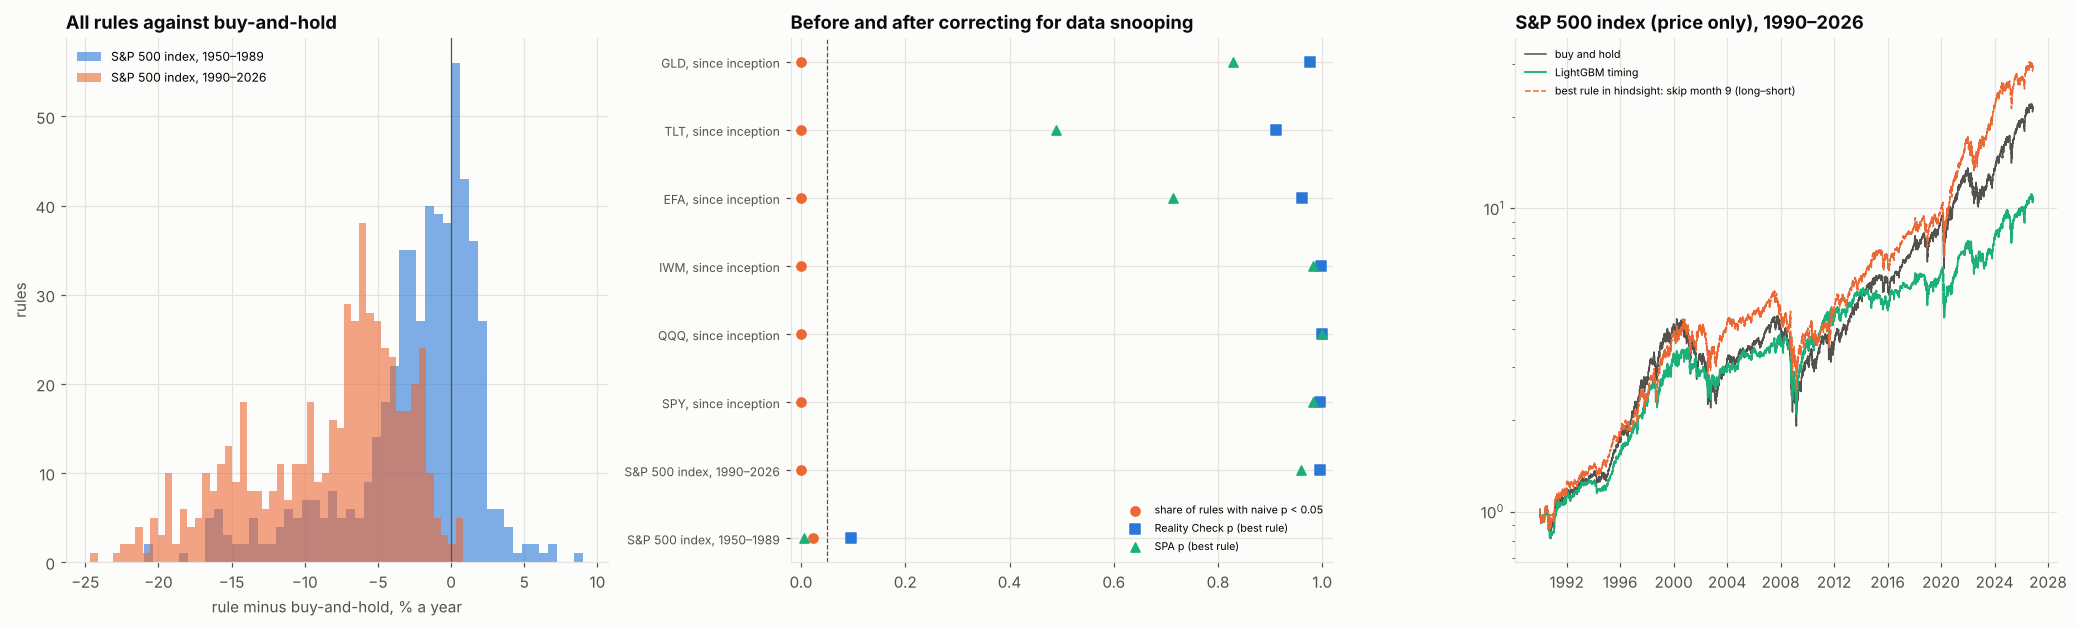

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.8))
a = ax[0]
for i, k in enumerate(
    ["S&P 500 index, 1950–1989", "S&P 500 index, 1990–2026"]
):
    D = RET[k]
    ex = (
        (D.drop(columns="buy and hold").mean() - D["buy and hold"].mean())
        * 252
        * 100
    )
    a.hist(ex, bins=50, alpha=0.6, color=PALETTE[i], label=k)
a.axvline(0, color=INK_2, lw=0.8)
a.set_xlabel("rule minus buy-and-hold, % a year")
a.set_ylabel("rules")
a.set_title("All rules against buy-and-hold")
a.legend(fontsize=8)
a = ax[1]
y = np.arange(len(SNOOP))
a.scatter(
    SNOOP["rules with naive p < 0.05"] / SNOOP.rules,
    y,
    color=PALETTE[1],
    label="share of rules with naive p < 0.05",
)
a.scatter(
    SNOOP["Reality Check p"],
    y,
    color=PALETTE[0],
    marker="s",
    label="Reality Check p (best rule)",
)
a.scatter(
    SNOOP["SPA p"], y, color=PALETTE[2], marker="^", label="SPA p (best rule)"
)
a.axvline(0.05, color=INK_2, lw=0.8, ls="--")
a.set_yticks(y, SNOOP.index, fontsize=8)
a.set_xlim(-0.02, 1.02)
a.set_title("Before and after correcting for data snooping")
a.legend(fontsize=7, loc="lower right")
a = ax[2]
a.plot((1 + bh_ret).cumprod(), color=INK_2, lw=1, label="buy and hold")
a.plot(
    (1 + ml_ret).cumprod(), color=PALETTE[2], lw=1.2, label="LightGBM timing"
)
best90 = SNOOP.loc["S&P 500 index, 1990–2026", "best rule"]
a.plot(
    (1 + RET["S&P 500 index, 1990–2026"][best90]).cumprod(),
    color=PALETTE[1],
    lw=1,
    ls="--",
    label=f"best rule in hindsight: {best90}",
)
a.set_yscale("log")
a.set_title("S&P 500 index (price only), 1990–2026")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_technical_rules")
plt.show()

In [10]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Best rule vs buy-and-hold, % a year",
        "Reality Check and SPA p-values",
    ),
)
dash.add_trace(
    go.Bar(
        x=SNOOP.index,
        y=SNOOP["best rule % a year"],
        name="best rule",
        marker_color=PALETTE[1],
        text=SNOOP["best rule"],
        hovertemplate="%{text}<br>%{y:.1f}% a year<extra></extra>",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=SNOOP.index,
        y=SNOOP["buy and hold % a year"],
        name="buy and hold",
        marker_color=INK_2,
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=SNOOP.index,
        y=SNOOP["Reality Check p"],
        name="Reality Check p",
        marker_color=PALETTE[0],
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=SNOOP.index, y=SNOOP["SPA p"], name="SPA p", marker_color=PALETTE[2]
    ),
    1,
    2,
)
dash.add_hline(y=0.05, line_dash="dash", line_color=INK_2, row=1, col=2)
dash.update_layout(
    height=560,
    width=1450,
    template="simple_white",
    title="Technical trading rules under multiple-testing control",
    barmode="group",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 7. Reading the results and limitations

**Before 1990, simple rules really did beat the S&P 500 index.** In 1950–1989:
- **How many rules won:** 189 of 552 rules beat buy-and-hold after 5 bp per trade, and 13 had a naive *p*-value below 5%.
- **The best rule:** a 0.5% filter run long–short, which buys after a 0.5% rise from a low and goes short after a 0.5% fall from a high. It earned 17.7% a year against 7.5% for the index (price only), with a Sharpe ratio of 0.90 against 0.21.
- **After correcting for the search:** Hansen's SPA test rejects the null that no rule beats the market (*p* = 0.006), and White's Reality Check comes close (*p* = 0.095). On a risk-adjusted basis both reject (Reality Check *p* = 0.019, SPA *p* < 0.001), and nine rules survive the Holm correction.

This is the result of Brock, Lakonishok and LeBaron (1992) and Sullivan, Timmermann and White (1999). It is largely a feature of the index itself: before 1990 the prices of many smaller constituents were stale, so index returns were positively autocorrelated, and tiny filters captured that. Trading the actual stocks would not have earned it, and even 5 bp per trade is generous for 1950s costs.

**Since 1990, nothing survives.** For the S&P 500 index in 1990–2026:
- **Raw comparison:** only 7 of 552 rules beat buy-and-hold on raw returns. The best ("skip September", long–short) earned 9.6% against 8.7%, with a naive *p*-value of 0.63.
- **After correcting for the search:** the Reality Check gives *p* = 0.996 and SPA gives 0.96.
- **Risk-adjusted:** 41 rules have a higher Sharpe ratio than buy-and-hold, because they sit in Treasury bills during bear markets. None is significant after the Holm correction (SPA *p* = 0.72).

**The same holds for six ETFs since 2004–2007.** No best rule is significant after correcting for data snooping (SPA *p*-values 0.49–1.00), in either raw or risk-adjusted terms:

| ETF | Rules beating buy-and-hold | Best rule | SPA *p* |
|---|---|---|---|
| SPY | 5 | RSI(28) mean reversion | 0.98 |
| QQQ | 0 | — | 1.00 |
| IWM | 3 | skip September | 0.98 |
| EFA | 12 | RSI(28) mean reversion | 0.71 |
| TLT | 57 | skip October | 0.49 |
| GLD | 4 | skip June | 0.83 |

Long Treasuries are the only market where many rules beat buy-and-hold (57), mostly trend rules that stepped aside during the 2022 bond crash. Even there, the best is well within what searching 552 rules produces by chance.

**Naive testing is the trap.** Without correction, a researcher would report "13 significant rules" for 1950–1989 and several for each ETF in the risk-adjusted test. The Bonferroni correction is too harsh, since many of the 552 rules are near-duplicates. The Reality Check and SPA account for that correlation through the bootstrap, and they still find nothing after 1990.

**Machine learning does not rescue technical analysis.** A LightGBM model fed every indicator and retrained each year from 1990:
- **Accuracy:** it predicts the 5-day direction with an AUC of only 0.52.
- **Exposure:** it is invested 72% of the time.
- **Return:** it earns 6.7% a year against 8.7% for buy-and-hold, with a lower Sharpe ratio (0.48 vs 0.55, on total returns).
- **Drawdown:** it reduces the maximum drawdown from −57% to −46%. That is the usual result of timing models: less pain in crashes, paid for with missed rallies.

**Limits.**
- The S&P 500 index series excludes dividends (2–4% a year), which flatters rules that spend time in Treasury bills relative to buy-and-hold; the ETFs include them.
- Costs are a flat 5 bp per trade, with no shorting costs for the long–short versions.
- The rule set is broad but finite. A different universe could change which rule is best, though not the conclusion once the search is accounted for.
- The bootstrap uses an average block length of 10 days; other choices change the *p*-values somewhat.

In [11]:
SNOOP.to_csv(OUT_DIR / "data_snooping_tests.csv")
SNOOP_RS.to_csv(OUT_DIR / "data_snooping_tests_risk_scaled.csv")
ML.to_csv(OUT_DIR / "lightgbm_timing.csv")
pd.concat(
    {k: (v.mean() * 252).rename("annual mean") for k, v in RET.items()}, axis=1
).to_csv(OUT_DIR / "rule_annual_means.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_technical_rules.png, dashboard.html, dashboard.png, data_snooping_tests.csv, data_snooping_tests_risk_scaled.csv, lightgbm_timing.csv, rule_annual_means.csv


## References

- Yahoo Finance. S&P 500 index (^GSPC) and ETF daily prices. https://finance.yahoo.com/
- Federal Reserve Bank of St. Louis. FRED: 3-month Treasury bill rate (DTB3). https://fred.stlouisfed.org/series/DTB3
- CFA Institute. CFA Program Level I curriculum, Technical Analysis; Quantitative Methods: Hypothesis Testing.
- Brock, W., Lakonishok, J., & LeBaron, B. (1992). Simple technical trading rules and the stochastic properties of stock returns. *Journal of Finance*, 47(5), 1731–1764.
- Sullivan, R., Timmermann, A., & White, H. (1999). Data-snooping, technical trading rule performance, and the bootstrap. *Journal of Finance*, 54(5), 1647–1691. https://doi.org/10.1111/0022-1082.00163
- White, H. (2000). A reality check for data snooping. *Econometrica*, 68(5), 1097–1126. https://doi.org/10.1111/1468-0262.00152
- Hansen, P. R. (2005). A test for superior predictive ability. *Journal of Business & Economic Statistics*, 23(4), 365–380. https://doi.org/10.1198/073500105000000063
- Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association*, 89(428), 1303–1313.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.